In [1]:
import os
import glob
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model

In [2]:
TRAIN_IMG_DIR = "../Dataset/BraTS_2025/glioma split data/train/images"
TRAIN_MASK_DIR = "../Dataset/BraTS_2025/glioma split data/train/masks"

VAL_IMG_DIR = "../Dataset/BraTS_2025/glioma split data/val/images"
VAL_MASK_DIR = "../Dataset/BraTS_2025/glioma split data/val/masks"

In [3]:
train_images = sorted(glob.glob(os.path.join(TRAIN_IMG_DIR, "*.npy")))
train_masks  = sorted(glob.glob(os.path.join(TRAIN_MASK_DIR, "*.npy")))

val_images = sorted(glob.glob(os.path.join(VAL_IMG_DIR, "*.npy")))
val_masks  = sorted(glob.glob(os.path.join(VAL_MASK_DIR, "*.npy")))

print(len(train_images), len(train_masks))

66 66


In [4]:
x = np.load(train_images[0])
y = np.load(train_masks[0])

print("Image shape:", x.shape)
print("Mask shape:", y.shape)
print("Mask classes:", np.unique(y))

Image shape: (128, 128, 128, 4)
Mask shape: (128, 128, 128, 4)
Mask classes: [0. 1.]


In [5]:
def normalize(volume):
    return (volume - np.mean(volume)) / (np.std(volume) + 1e-8)

In [6]:
def extract_patch(img, mask, patch_size=64, max_tries=10):
    h, w, d = img.shape[:3]

    for _ in range(max_tries):
        x = np.random.randint(0, h - patch_size)
        y = np.random.randint(0, w - patch_size)
        z = np.random.randint(0, d - patch_size)

        img_patch = img[x:x+patch_size, y:y+patch_size, z:z+patch_size]
        mask_patch = mask[x:x+patch_size, y:y+patch_size, z:z+patch_size]

        # Reject empty patches
        if np.sum(mask_patch) > 0:
            return img_patch, mask_patch

    return img_patch, mask_patch  # fallback

In [7]:
class DataGenerator(tf.keras.utils.Sequence):
    def __init__(self, image_files, mask_files, batch_size=2):
        self.image_files = image_files
        self.mask_files = mask_files
        self.batch_size = batch_size

    def __len__(self):
        return len(self.image_files) // self.batch_size

    def __getitem__(self, idx):
        batch_imgs = self.image_files[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_masks = self.mask_files[idx*self.batch_size:(idx+1)*self.batch_size]

        X, Y = [], []

        for img_path, mask_path in zip(batch_imgs, batch_masks):
            img = np.load(img_path)
            mask = np.load(mask_path)

            img = normalize(img)

            img, mask = extract_patch(img, mask)

            X.append(img)
            Y.append(mask)

        return np.array(X), np.array(Y)

In [8]:
train_gen = DataGenerator(train_images, train_masks, batch_size=2)
val_gen   = DataGenerator(val_images, val_masks, batch_size=2)


In [9]:
def conv_block(x, filters):
    x = layers.Conv3D(filters, 3, padding="same", activation="relu")(x)
    x = layers.Conv3D(filters, 3, padding="same", activation="relu")(x)
    return x

def build_unet(input_shape=(64,64,64,4)):
    inputs = layers.Input(input_shape)

    c1 = conv_block(inputs, 32)
    p1 = layers.MaxPool3D()(c1)

    c2 = conv_block(p1, 64)
    p2 = layers.MaxPool3D()(c2)

    c3 = conv_block(p2, 128)
    p3 = layers.MaxPool3D()(c3)

    c4 = conv_block(p3, 256)

    u1 = layers.UpSampling3D()(c4)
    u1 = layers.concatenate([u1, c3])
    c5 = conv_block(u1, 128)

    u2 = layers.UpSampling3D()(c5)
    u2 = layers.concatenate([u2, c2])
    c6 = conv_block(u2, 64)

    u3 = layers.UpSampling3D()(c6)
    u3 = layers.concatenate([u3, c1])
    c7 = conv_block(u3, 32)

    # OUTPUT
    outputs = layers.Conv3D(4, 1, activation="sigmoid")(c7)

    return Model(inputs, outputs)

In [10]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.reshape(y_true, [-1, 4])
    y_pred = tf.reshape(y_pred, [-1, 4])

    intersection = tf.reduce_sum(y_true * y_pred)
    denominator = tf.reduce_sum(y_true + y_pred)

    return 1 - (2. * intersection + smooth) / (denominator + smooth)

In [11]:
def combined_loss(y_true, y_pred):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    d_loss = dice_loss(y_true, y_pred)
    return bce + d_loss

In [12]:
model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=combined_loss,
    metrics=[]
)

In [13]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30
)

e:\Research\venv\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 123s 4s/step - loss: 0.6833 - val_loss: 0.5723
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - loss: 0.5168 - val_loss: 0.3333
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - loss: 0.4592 - val_loss: 0.3938
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - loss: 0.4200 - val_loss: 0.4943
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 97s 3s/step - loss: 0.4425 - val_loss: 0.4396
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - loss: 0.4015 - val_loss: 0.2988
Epoch 7/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 118s 4s/step - loss: 0.3345 - val_loss: 0.2885
Epoch 8/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 122s 4s/step - loss: 0.4056 - val_loss: 0.4391
Epoch 9/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 109s 3s/step - loss: 0.4018 - val_loss: 0.4561
Epoch 10/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 109s 3s/step - loss: 0.3380 - val_loss: 0.5723
Epoch 11/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 107s 3s/step - loss: 0.4260 - val_loss: 0.3448
Epoch 12/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - loss: 0.371

In [14]:
model.save("brats_unet_final.keras")

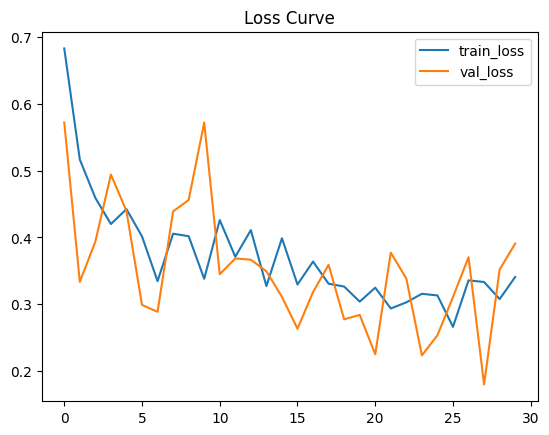

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.title("Loss Curve")
plt.show()

In [18]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    y_true = tf.reshape(y_true, [-1, 4])
    y_pred = tf.reshape(y_pred, [-1, 4])

    intersection = tf.reduce_sum(y_true * y_pred)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true + y_pred) + smooth)

In [19]:
model.compile(
    optimizer='adam',
    loss=combined_loss,
    metrics=[dice_coef]
)

model.evaluate(val_gen)

6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - dice_coef: 0.8424 - loss: 0.3131


[0.3131381869316101, 0.8424111008644104]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


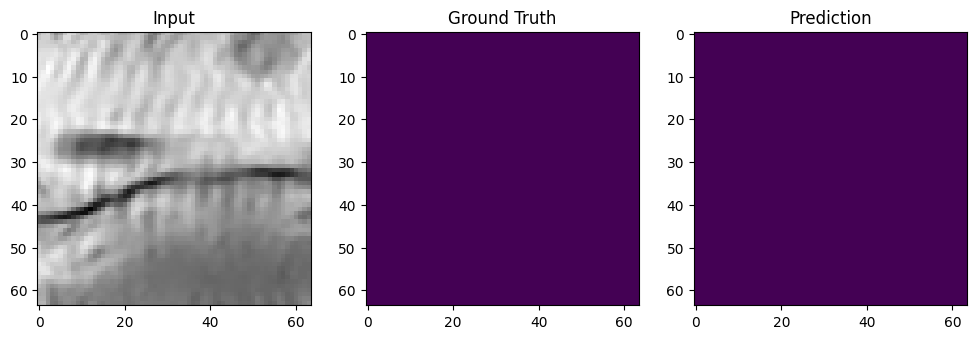

In [20]:
import numpy as np

# get one batch
X, Y = val_gen[0]
pred = model.predict(X)

# pick sample + slice
i = 0
slice_idx = 32

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(X[i,:,:,slice_idx,0], cmap='gray')
plt.title("Input")

plt.subplot(1,3,2)
plt.imshow(Y[i,:,:,slice_idx,1])  # ground truth channel
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred[i,:,:,slice_idx,1] > 0.5)
plt.title("Prediction")

plt.show()